# AI Predictive Maintenance — Clean EDA & Baseline Modeling

**Dataset:** AI4I 2020 Predictive Maintenance  
**Goal:** Explore machine operating data, prepare it correctly, handle class imbalance, and build baseline models for predicting `Machine failure`.

> Place `ai4i2020.csv` in the same folder as this notebook before running it.
>
> This notebook is a cleaned and improved version of the first notebook.

#Member Group

1.   Mohammad NoorAldeen Mohammad

2.   Ahmad Hasan Muhsen

3.   bassam Alshorman



## 1. Import libraries and settings


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, f1_score, matthews_corrcoef, balanced_accuracy_score)

from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TARGET = "Machine failure"

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [ ]:
df = pd.read_csv("ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Initial data inspection

We check the original dataset size, column types, missing values, duplicate rows, and basic statistics before changing anything.

In [ ]:
original_shape = df.shape

print(f"Original dataset: {original_shape[0]:,} rows × {original_shape[1]} columns")

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nNumber of duplicated rows:")
print(df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe().T)

Original dataset: 10,000 rows × 14 columns

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF         

,Missing values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Number of duplicated rows:
0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## 4. Explore the target and product type

The target is highly imbalanced: most records represent normal operation (`0`), while a small number represent machine failure (`1`).

Machine failure
0    9661
1     339
Name: count, dtype: int64


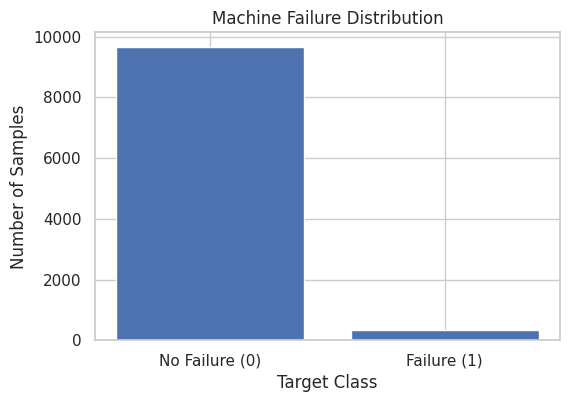

In [ ]:
target_counts = df["Machine failure"].value_counts()

print(target_counts)

target_counts = df["Machine failure"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["No Failure (0)", "Failure (1)"],
    target_counts.values
)

plt.title("Machine Failure Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")

plt.show()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


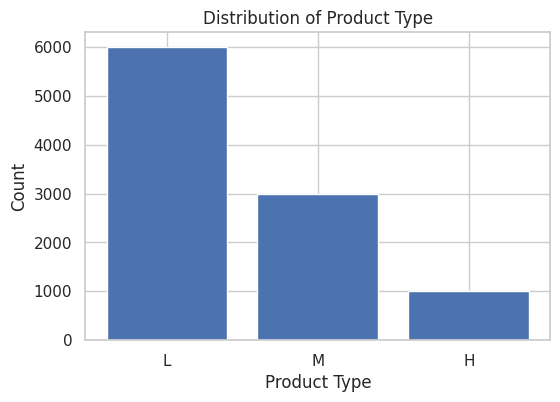

In [ ]:
type_counts = df["Type"].value_counts()

print(type_counts)

type_counts = df["Type"].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(type_counts.index, type_counts.values)

plt.title("Distribution of Product Type")
plt.xlabel("Product Type")
plt.ylabel("Count")

plt.show()

## 5. Remove identifiers and target-leakage columns

- `UDI` and `Product ID` are identifiers, not useful operating measurements for this prediction task.
- `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` describe failure modes. Using them to predict `Machine failure` could reveal information about the target and create **target leakage**.

We keep `Type`, the five operating measurements, and the target.

In [ ]:
ID_COLUMNS = ["UDI", "Product ID"]
LEAKAGE_COLUMNS = ["TWF", "HDF", "PWF", "OSF", "RNF"]

columns_to_drop = [
    col for col in ID_COLUMNS + LEAKAGE_COLUMNS
    if col in df.columns
]

df_clean = df.drop(columns=columns_to_drop).copy()

print("Columns removed:", columns_to_drop)
print(f"Before cleaning: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"After cleaning:  {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

display(df_clean.head())

Columns removed: ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Before cleaning: 10,000 rows × 14 columns
After cleaning:  10,000 rows × 7 columns


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 6. Check potential outliers

**Important:** An outlier is not automatically an error. In predictive maintenance, unusual speed or torque values may be meaningful warning signals. We identify and inspect them; we do not delete them automatically.

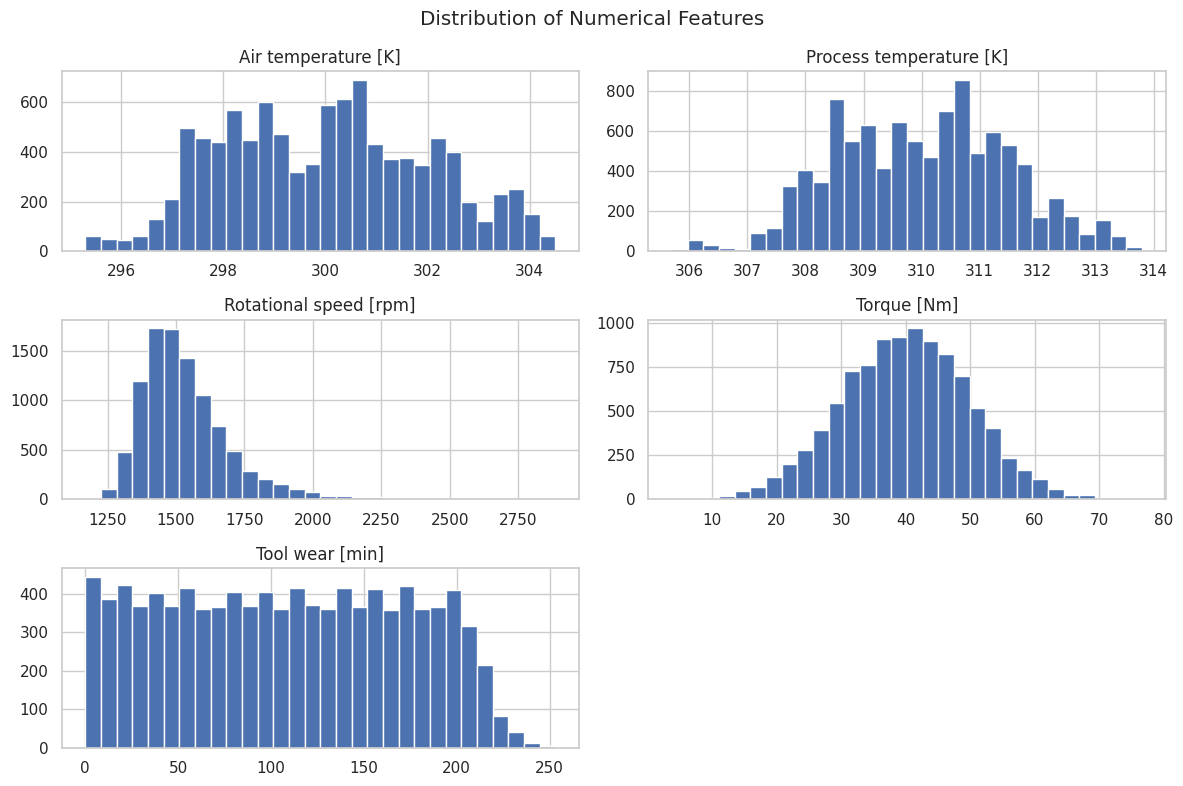

In [ ]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df_clean[numerical_features].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

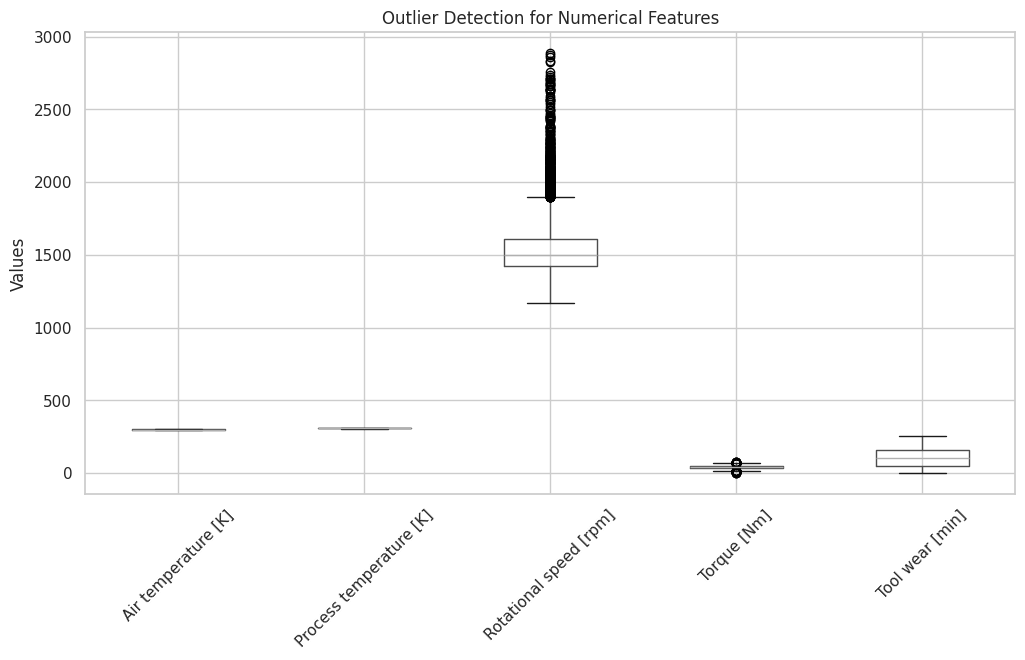

In [ ]:
plt.figure(figsize=(12, 6))

df_clean[numerical_features].boxplot(
    rot=45
)

plt.title("Outlier Detection for Numerical Features")
plt.ylabel("Values")
plt.show()

## 7. Feature engineering

We add three candidate features while retaining the original measurements:

- `Temp_Diff`: process temperature minus air temperature.
- `Mechanical_Power_kW`: calculated using torque × angular velocity. This is a physically meaningful power calculation.
- `ToolWear_Torque_Interaction`: an interaction feature that may help the model represent the combined effect of tool wear and torque. It is an engineered indicator, not a direct physical measurement.

In [ ]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=["Type"],
    drop_first=True,
    dtype=int
)

df_encoded.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,1,0
2,298.1,308.5,1498,49.4,5,0,1,0
3,298.2,308.6,1433,39.5,7,0,1,0
4,298.2,308.7,1408,40.0,9,0,1,0


In [ ]:
df_encoded['Temp_Diff'] = df_encoded['Process temperature [K]'] - df_encoded['Air temperature [K]']

df_encoded['Power'] = df_encoded['Rotational speed [rpm]'] * df_encoded['Torque [Nm]']

df_encoded['Tool_Strain'] = df_encoded['Tool wear [min]'] * df_encoded['Torque [Nm]']

## 8. Correlation analysis

The heatmap includes the target so we can inspect simple linear associations with `Machine failure`. Correlation does not prove causation, and low correlation does not automatically mean a feature is useless to a non-linear model such as Random Forest.

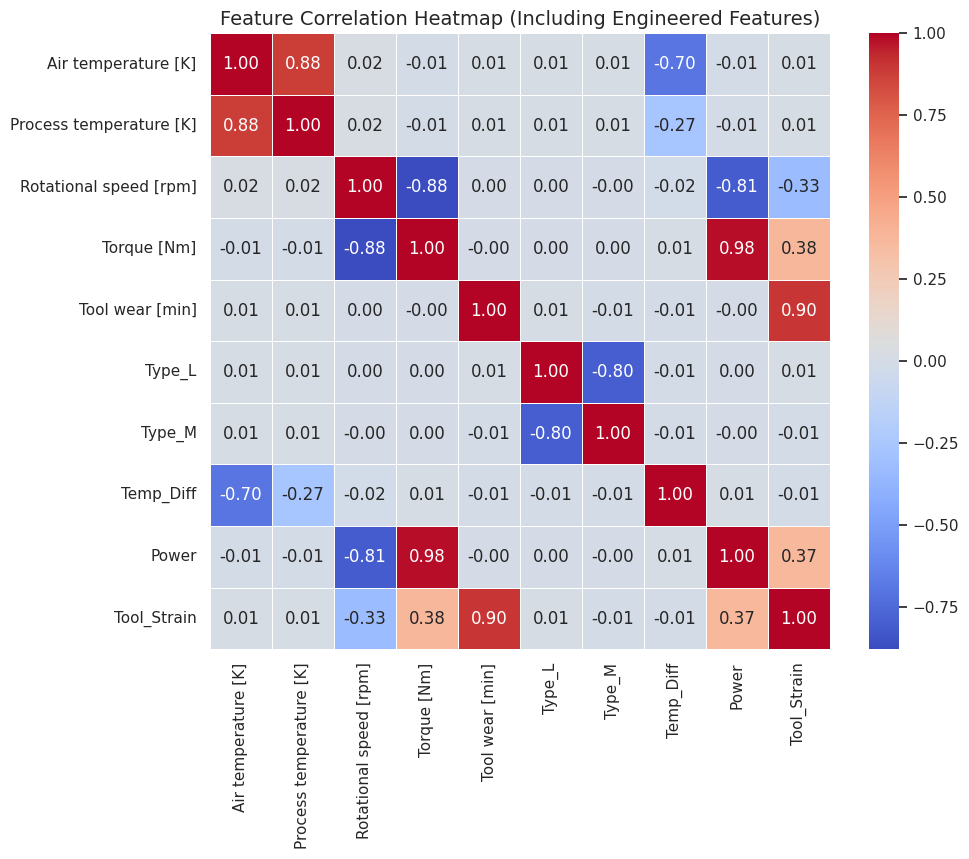

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df_encoded.drop(columns=["Machine failure"]).corr().round(2)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap (Including Engineered Features)", fontsize=14)
plt.show()

In [ ]:
df_model = df_encoded.drop(
  columns=["Process temperature [K]", "Air temperature [K]", "Torque [Nm]"]
)

print(df_model.columns.tolist())
print(df_model.shape)

['Rotational speed [rpm]', 'Tool wear [min]', 'Machine failure', 'Type_L', 'Type_M', 'Temp_Diff', 'Power', 'Tool_Strain']
(10000, 8)


## 9. Compare dataset dimensions before and after preparation

This comparison shows how many rows and columns remain after removing identifiers/leakage columns and after adding engineered features.

,Stage,Rows,Columns
0,Original dataset,10000,14
1,After removing IDs and leakage columns,10000,7
2,After feature engineering,10000,8


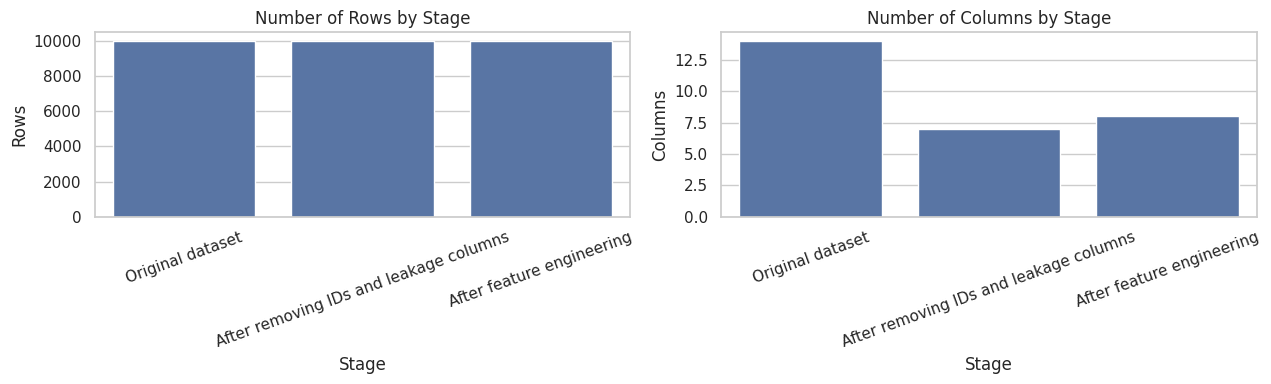

In [ ]:
shape_stages = pd.DataFrame({
    "Stage": [
        "Original dataset",
        "After removing IDs and leakage columns",
        "After feature engineering"
    ],
    "Rows": [
        df.shape[0],
        df_clean.shape[0],
        df_model.shape[0]
    ],
    "Columns": [
        df.shape[1],
        df_clean.shape[1],
        df_model.shape[1]
    ]
})

display(shape_stages)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=shape_stages, x="Stage", y="Rows", ax=axes[0])
axes[0].set_title("Number of Rows by Stage")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=shape_stages, x="Stage", y="Columns", ax=axes[1])
axes[1].set_title("Number of Columns by Stage")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 10. Split the data into training and testing sets also Scale numerical training features

We split before applying any resampling. `stratify=y` keeps approximately the same failure ratio in both sets.

- Training set: used to fit the models and apply resampling.
- Test set: kept untouched to evaluate how the models perform on unseen, naturally imbalanced data.

Random Forest itself does not require feature scaling. We scale the numerical features

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_model.drop(columns=["Machine failure"])
y = df_model["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scale_cols = [
    "Rotational speed [rpm]",
    "Tool wear [min]",
    "Temp_Diff",
    "Power",
    "Tool_Strain"
]

scaler = StandardScaler()

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("حجم بيانات التدريب:", X_train.shape)
print("حجم بيانات الاختبار:", X_test.shape)

حجم بيانات التدريب: (8000, 7)
حجم بيانات الاختبار: (2000, 7)


## 12. Apply SMOTE to the training data only

SMOTE adds synthetic minority-class examples; it does not simply copy rows.

In [ ]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\n Number of cases in the training data before SMOTE:")
print(y_train.value_counts())

print("\n Number of cases in the training data After SMOTE")
print(y_train_smote.value_counts())


 Number of cases in the training data before SMOTE:
Machine failure
0    7729
1     271
Name: count, dtype: int64

 Number of cases in the training data After SMOTE
Machine failure
0    7729
1    7729
Name: count, dtype: int64


In [ ]:
print("Data shape after SMOTE:", X_train_smote.shape)


Data shape after SMOTE: (15458, 7)


In [ ]:
failures_data = X_train_smote[y_train_smote == 1]

duplicates_count = failures_data.duplicated().sum()

print(f"Exact duplicates in Class 1 (Failures) after SMOTE: {duplicates_count}")

Exact duplicates in Class 1 (Failures) after SMOTE: 0


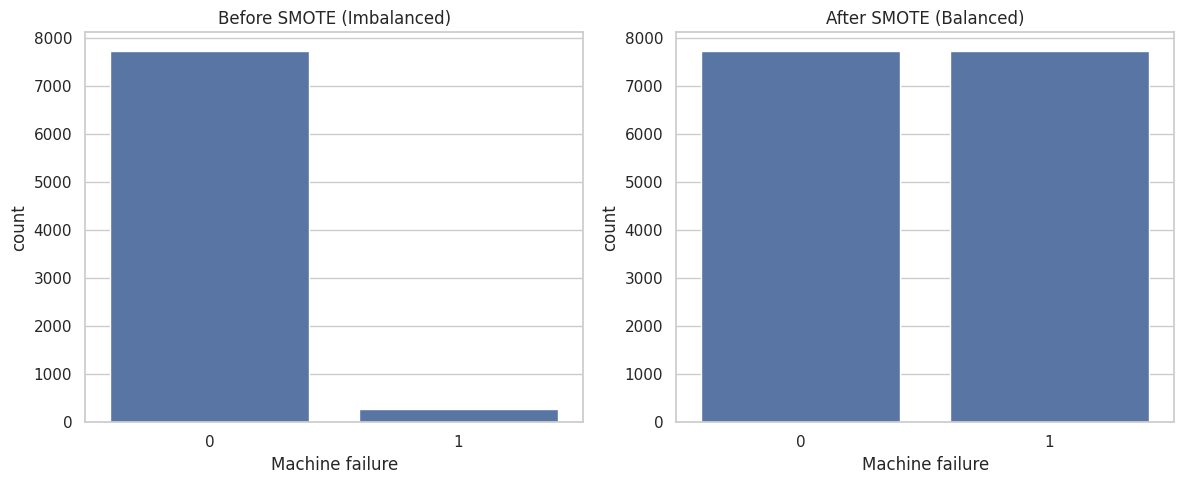

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x=y_train, ax=axes[0]).set_title("Before SMOTE (Imbalanced)")
sns.countplot(x=y_train_smote, ax=axes[1]).set_title("After SMOTE (Balanced)")
plt.tight_layout()
plt.show()

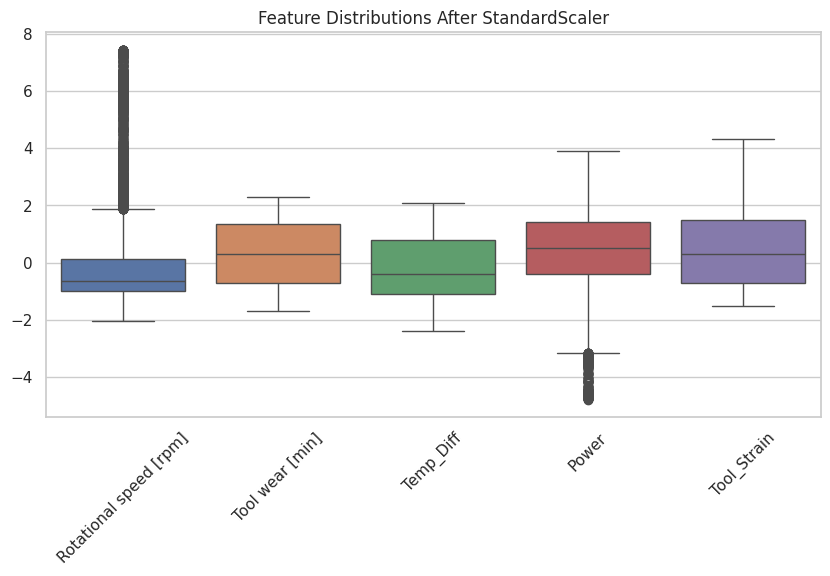

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=X_train_smote[scale_cols])
plt.title("Feature Distributions After StandardScaler")
plt.xticks(rotation=45)
plt.show()

#Model Experiments

In this section, we train three Random Forest configurations using the same engineered features and the same train-test split. Each experiment applies a different strategy to handle class imbalance

In [ ]:
models = {
    "Baseline RF + SMOTE": RandomForestClassifier(
        random_state=42
    ),

    "RF without SMOTE": RandomForestClassifier(
        random_state=42
    ),

    "RF + Class Weights": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        min_samples_leaf=3,
        random_state=42
    )
}

predictions = {}
probabilities = {}

for name, model in models.items():

    if name == "Baseline RF + SMOTE":
        X_fit = X_train_smote
        y_fit = y_train_smote

    else:
        X_fit = X_train
        y_fit = y_train

    model.fit(X_fit, y_fit)

    predictions[name] = model.predict(X_test)

    positive_index = list(model.classes_).index(1)

    probabilities[name] = model.predict_proba(X_test)[:, positive_index]

    print(f"{name} trained successfully!")

print("\nAll experiments completed successfully.")

Baseline RF + SMOTE trained successfully!
RF without SMOTE trained successfully!
RF + Class Weights trained successfully!

All experiments completed successfully.


#Model Evaluation

Each model is evaluated using classification metrics and visualizations to understand its ability to detect machine failures.


MODEL EVALUATION: Baseline RF + SMOTE


,precision,recall,f1-score,support
No Failure (0),0.995,0.981,0.988,1932.000
Failure (1),0.611,0.853,0.712,68.000
accuracy,0.976,0.976,0.976,0.976
macro avg,0.803,0.917,0.850,2000.000
weighted avg,0.982,0.976,0.978,2000.000


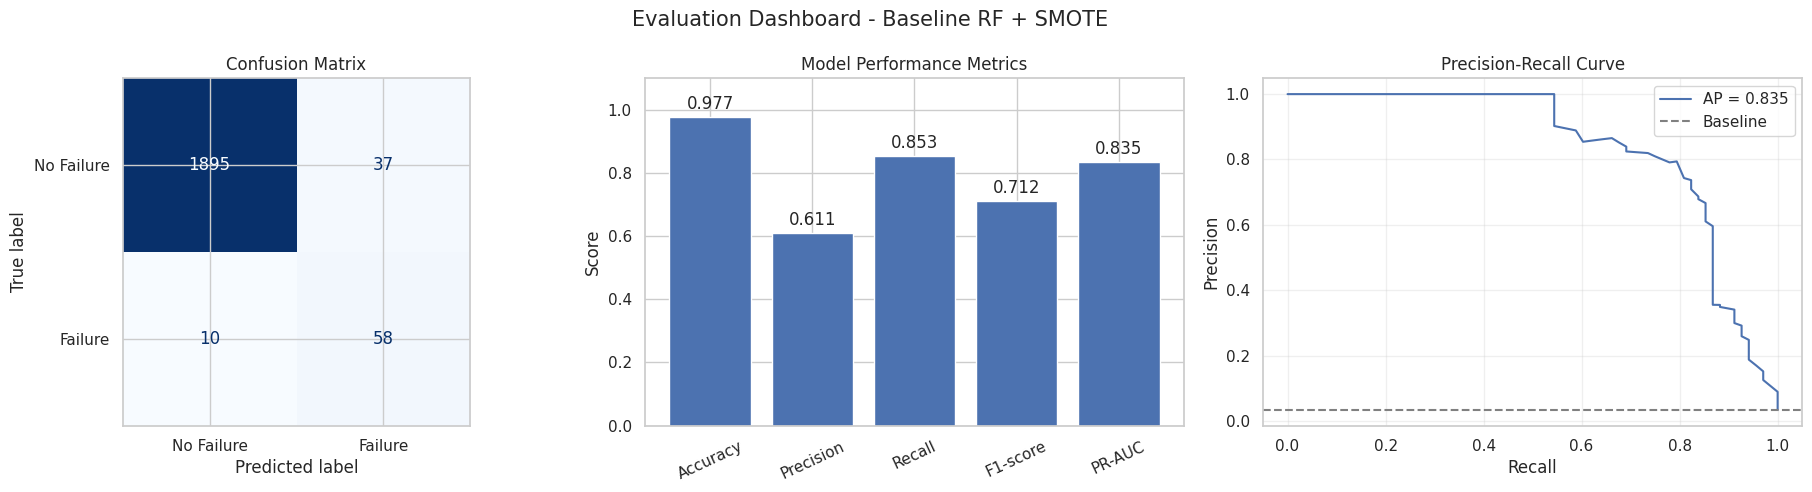


MODEL EVALUATION: RF without SMOTE


,precision,recall,f1-score,support
No Failure (0),0.993,0.999,0.996,1932.000
Failure (1),0.965,0.809,0.880,68.000
accuracy,0.992,0.992,0.992,0.992
macro avg,0.979,0.904,0.938,2000.000
weighted avg,0.992,0.992,0.992,2000.000


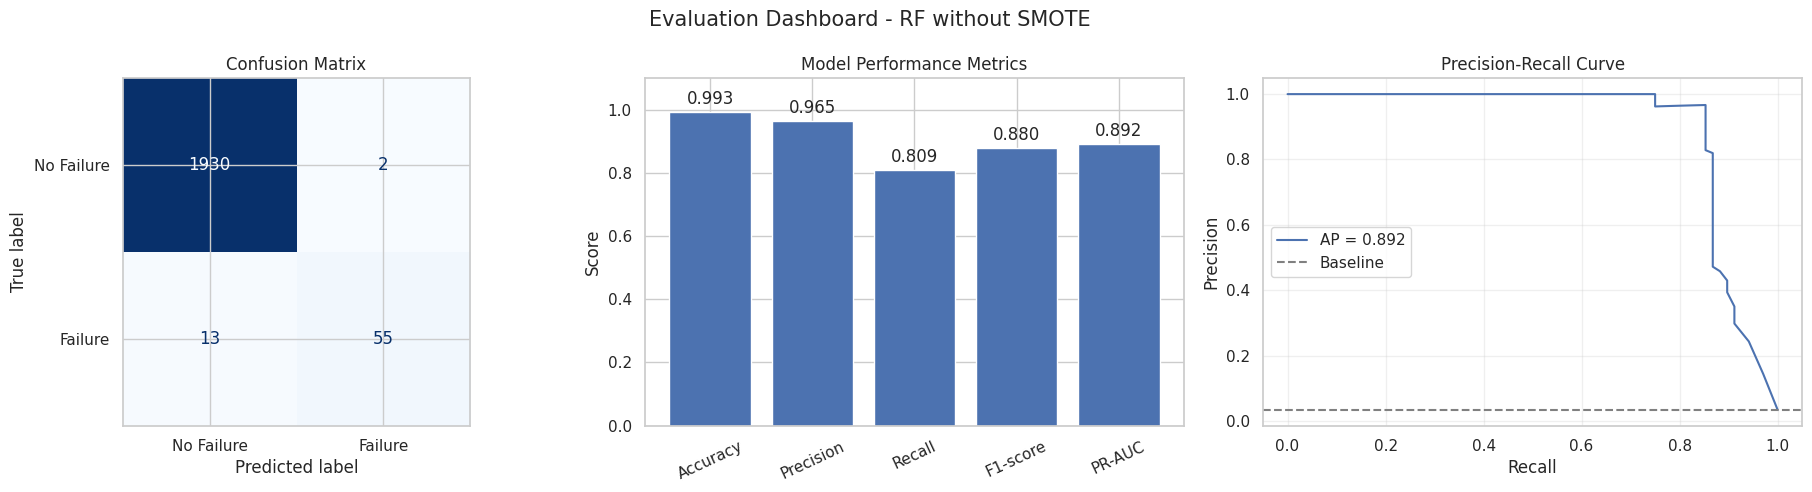


MODEL EVALUATION: RF + Class Weights


,precision,recall,f1-score,support
No Failure (0),0.995,0.998,0.996,1932.000
Failure (1),0.935,0.853,0.892,68.000
accuracy,0.993,0.993,0.993,0.993
macro avg,0.965,0.925,0.944,2000.000
weighted avg,0.993,0.993,0.993,2000.000


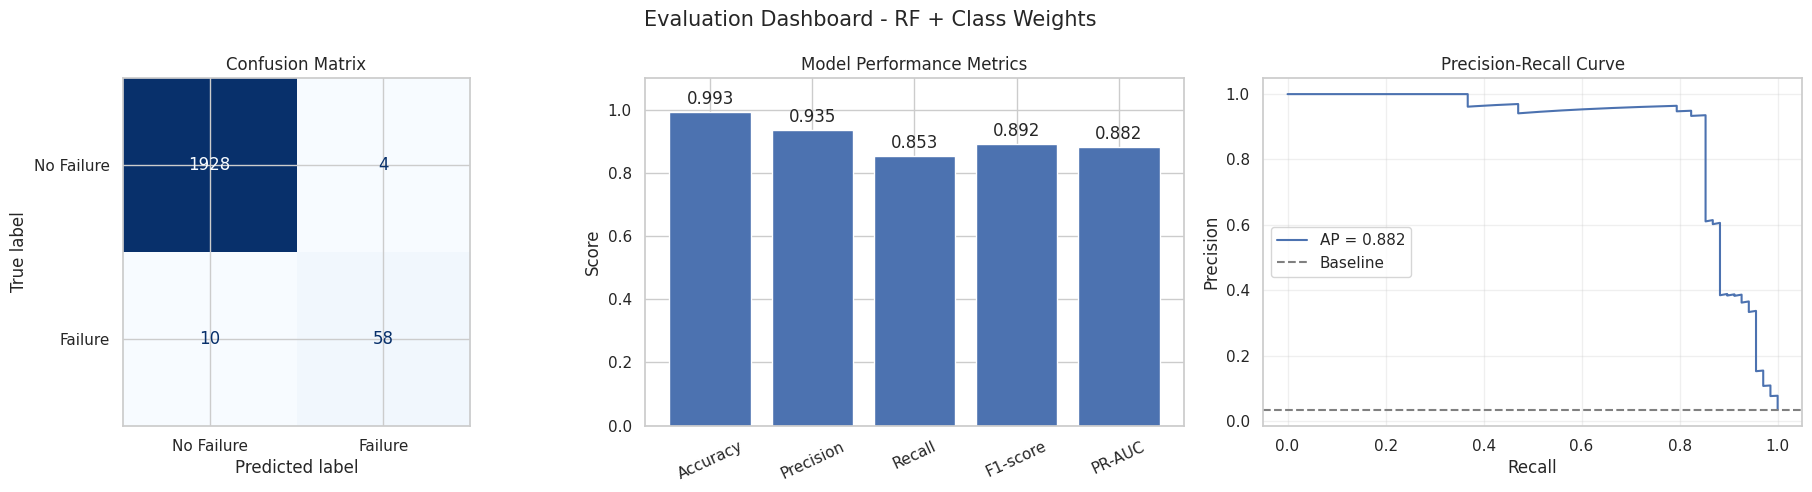

In [ ]:

evaluation_results = []

for name in models:

    y_pred = predictions[name]
    y_prob = probabilities[name]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    pr_auc = average_precision_score(y_test, y_prob)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "PR-AUC (AP)": pr_auc,
        "False Alarms (FP)": fp,
        "Missed Failures (FN)": fn
    })

    print("\n" + "=" * 65)
    print(f"MODEL EVALUATION: {name}")
    print("=" * 65)

    report = classification_report(
        y_test,
        y_pred,
        target_names=["No Failure (0)", "Failure (1)"],
        output_dict=True,
        zero_division=0
    )

    display(pd.DataFrame(report).T.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Failure", "Failure"]
    )

    disp.plot(
        ax=axes[0],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    axes[0].set_title("Confusion Matrix")

    metric_names = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "PR-AUC"
    ]

    metric_values = [
        accuracy,
        precision,
        recall,
        f1,
        pr_auc
    ]

    bars = axes[1].bar(metric_names, metric_values)

    axes[1].bar_label(
        bars,
        fmt="%.3f",
        padding=3
    )

    axes[1].set_ylim(0, 1.1)
    axes[1].set_title("Model Performance Metrics")
    axes[1].set_ylabel("Score")
    axes[1].tick_params(axis="x", rotation=25)

    pr_precision, pr_recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    axes[2].plot(
        pr_recall,
        pr_precision,
        label=f"AP = {pr_auc:.3f}"
    )

    axes[2].axhline(
        y=y_test.mean(),
        linestyle="--",
        color="gray",
        label="Baseline"
    )

    axes[2].set_title("Precision-Recall Curve")
    axes[2].set_xlabel("Recall")
    axes[2].set_ylabel("Precision")
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.suptitle(
        f"Evaluation Dashboard - {name}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

#Model Comparison

This section compares all trained models using the same evaluation metrics to identify the most suitable configuration for predictive maintenance

,Accuracy,Precision,Recall,F1-score,PR-AUC (AP),False Alarms (FP),Missed Failures (FN)
Model,,,,,,,
Baseline RF + SMOTE,97.65%,61.05%,85.29%,71.17%,83.54%,37,10
RF without SMOTE,99.25%,96.49%,80.88%,88.00%,89.20%,2,13
RF + Class Weights,99.30%,93.55%,85.29%,89.23%,88.19%,4,10


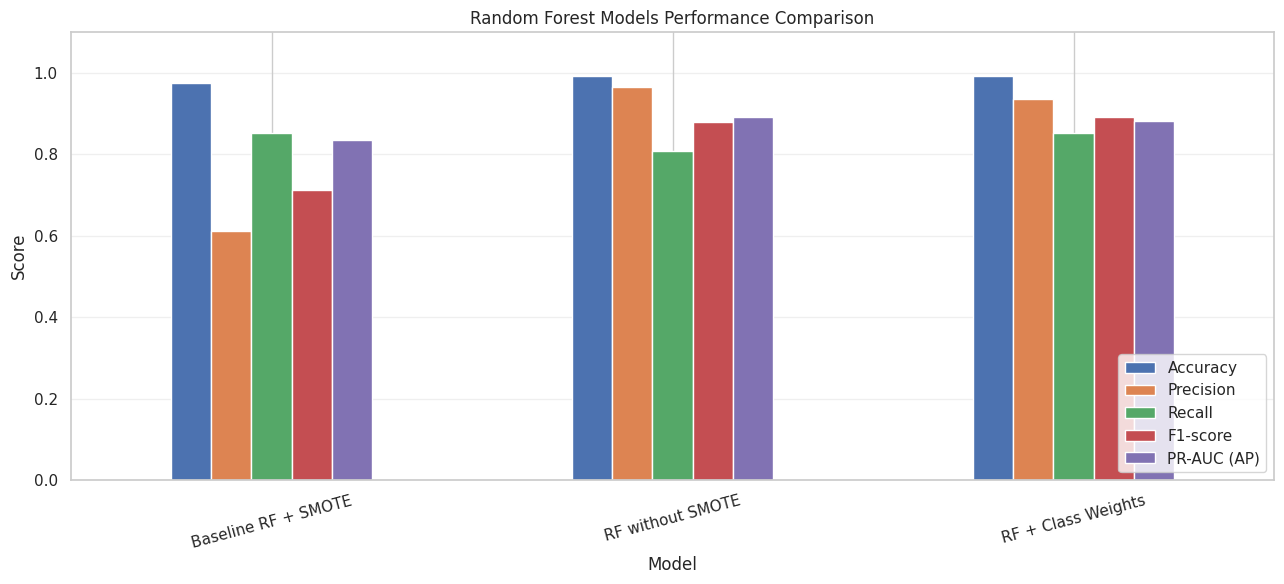

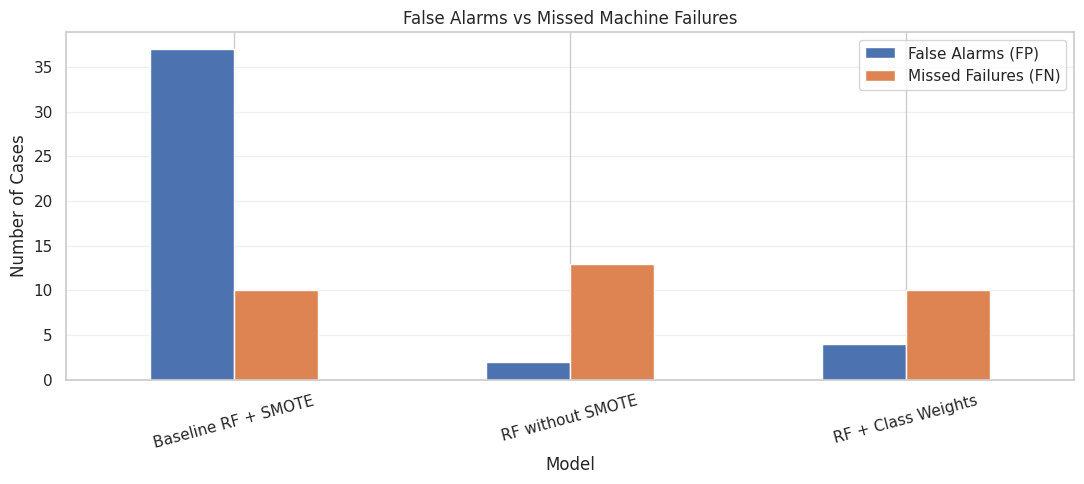

In [ ]:

comparison_df = pd.DataFrame(
    evaluation_results
).set_index("Model")

display(
    comparison_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "PR-AUC (AP)": "{:.2%}",
        "False Alarms (FP)": "{:.0f}",
        "Missed Failures (FN)": "{:.0f}"
    }).highlight_max(
        subset=["Recall", "F1-score", "PR-AUC (AP)"],
        color="#d9ead3"
    )
)

metrics_to_compare = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "PR-AUC (AP)"
]

ax = comparison_df[metrics_to_compare].plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title("Random Forest Models Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1.1)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


ax = comparison_df[
    ["False Alarms (FP)", "Missed Failures (FN)"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("False Alarms vs Missed Machine Failures")
ax.set_ylabel("Number of Cases")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#Feature Importance Analysis

This section identifies the most influential features used by the selected Random Forest model to predict machine failures.

,Feature,Importance
0,Rotational speed [rpm],0.2742
5,Power,0.2672
1,Tool wear [min],0.1533
4,Temp_Diff,0.1470
6,Tool_Strain,0.1467
2,Type_L,0.0059
3,Type_M,0.0056


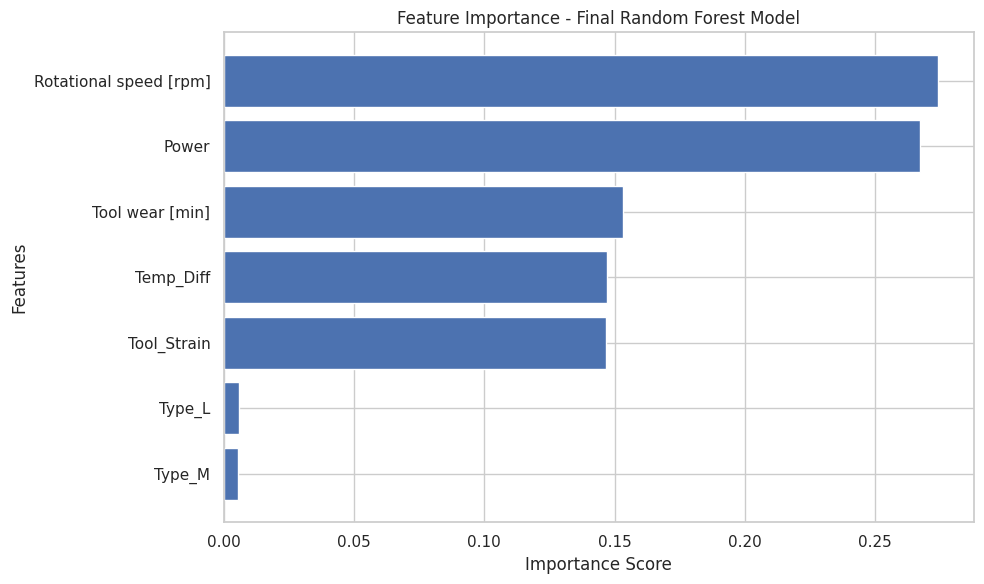

In [ ]:


final_model = models["RF + Class Weights"]

if hasattr(X_train, "columns"):
    feature_names = list(X_train.columns)
else:
    feature_names = [
        "Rotational speed [rpm]",
        "Tool wear [min]",
        "Type_L",
        "Type_M",
        "Temp_Diff",
        "Power",
        "Tool_Strain"
    ]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.round(4))

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Feature Importance - Final Random Forest Model")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

#Cross Validation

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

cv_strategy = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "pr_auc": "average_precision"
}

cv_results = cross_validate(
    final_model,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring,
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score", "PR-AUC"],
    "Mean": [
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_pr_auc"].mean()
    ],
    "Std": [
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_pr_auc"].std()
    ]
})

display(cv_summary.round(4))

,Metric,Mean,Std
0,Precision,0.9229,0.0470
1,Recall,0.8315,0.0442
2,F1-score,0.8732,0.0267
3,PR-AUC,0.8926,0.0293


##  Limitations & Future Work

### Limitations

Although the proposed model achieved promising results, this project has some limitations:

1. **Synthetic Dataset:** The AI4I 2020 dataset is a synthetic dataset, and its patterns may not fully represent real-world industrial environments.

2. **Class Imbalance:** Machine failure cases represent only a small percentage of the dataset, making failure detection more challenging.

3. **Limited Features:** The model depends on the available sensor measurements and engineered features. Additional industrial sensor data may improve prediction performance.

4. **Model Generalization:** The model has been evaluated using a specific dataset and train-test split. Its performance on different machines and real industrial environments still needs to be tested.

5. **Feature Importance:** Random Forest feature importance indicates how useful features are for the model's predictions, but it does not prove a causal relationship with machine failure.

### Future Work

Several improvements can be considered in future versions of this project:

1. Test the model using real industrial sensor data.
2. Experiment with additional machine learning algorithms such as XGBoost, LightGBM, and Gradient Boosting.
3. Apply hyperparameter optimization to improve model performance.
4. Experiment with different classification thresholds to balance missed failures and false alarms.
5. Explore time-series analysis and anomaly detection techniques.
6. Develop a real-time predictive maintenance system that monitors machine conditions and sends early warnings.